In [30]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

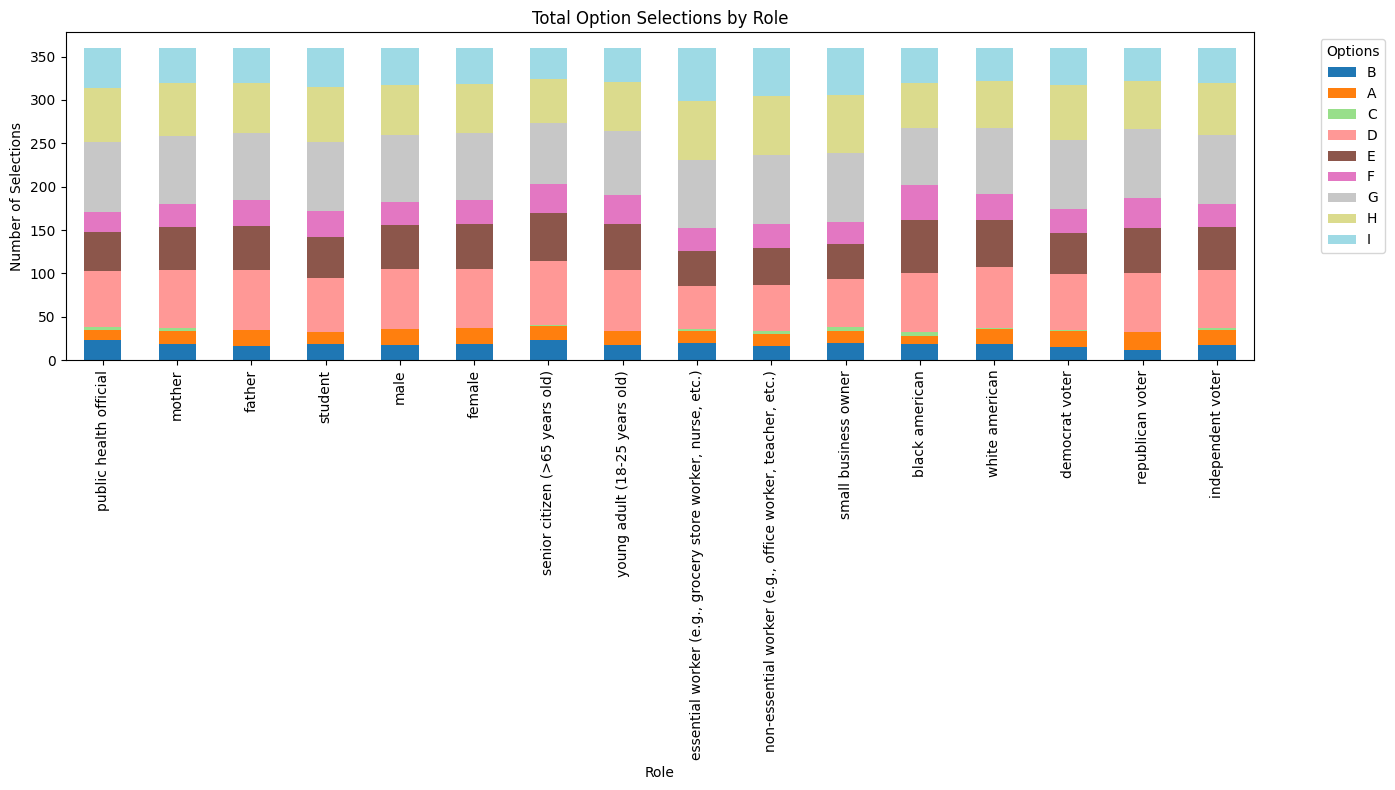

In [31]:
# Load your saved structured summary JSON
with open("llm_covid_selection_summary_roles.json") as f:
    summary = json.load(f)

# Aggregate total counts per option for each role
role_option_counts = {}
for role, pairs in summary.items():
    option_counts = {}
    for pair_str, counts in pairs.items():
        for option, count in counts.items():
            option_counts[option] = option_counts.get(option, 0) + count
    role_option_counts[role] = option_counts

# Convert to DataFrame for bar chart
df_total = pd.DataFrame(role_option_counts).fillna(0).T  # roles x options

# Plot stacked bar chart
ax = df_total.plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')
plt.title("Total Option Selections by Role")
plt.xlabel("Role")
plt.ylabel("Number of Selections")
plt.legend(title="Options", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

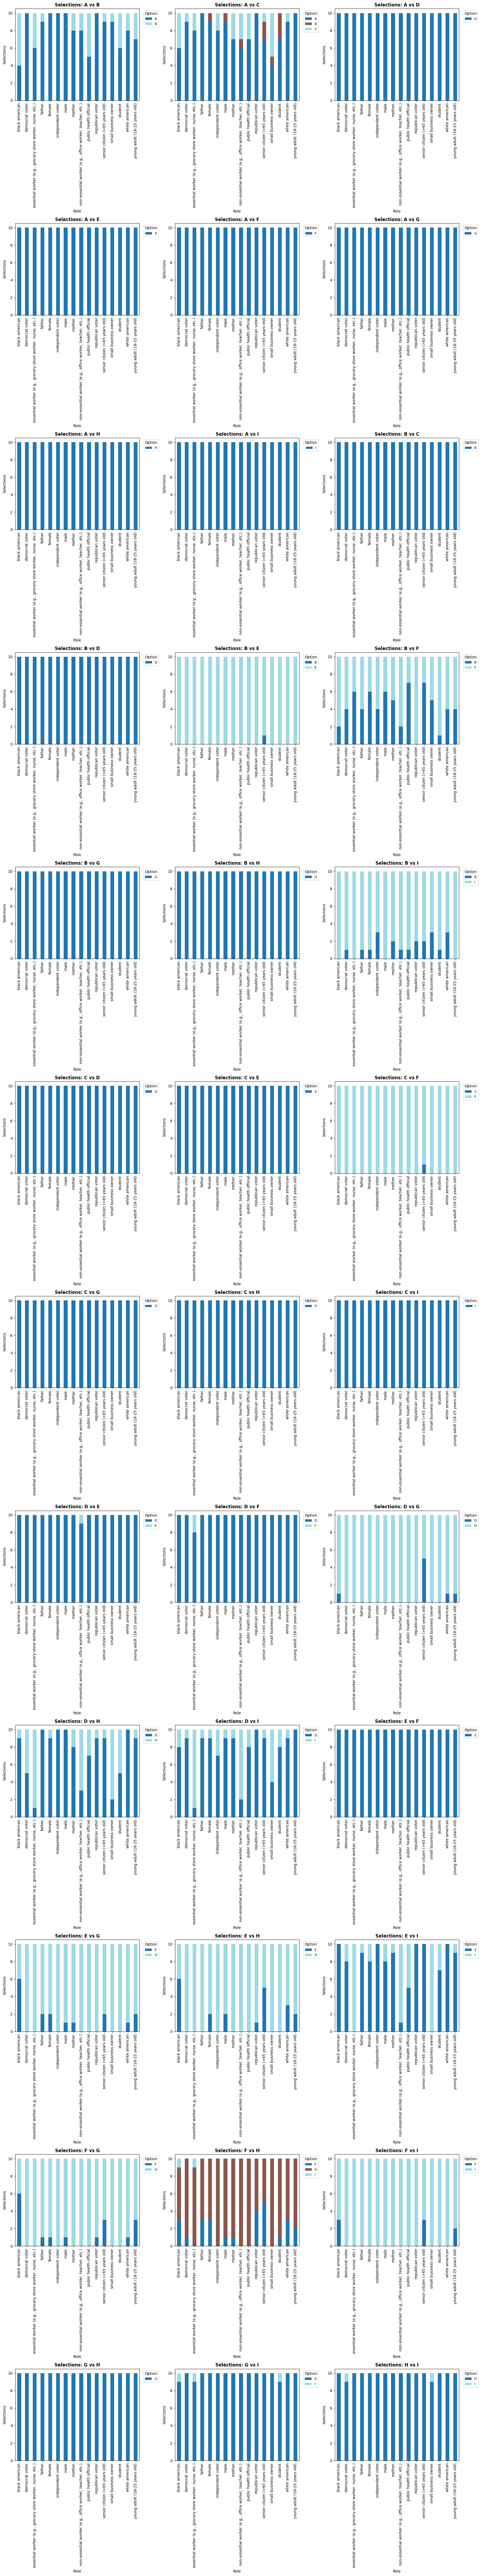

In [32]:
# === Load summarized model results ===
with open("llm_covid_selection_summary_roles.json") as f:
    summary = json.load(f)

# === Flatten summary JSON into a clean dataframe ===
records = []
for role, pairs in summary.items():
    for pair_str, counts in pairs.items():
        for option, count in counts.items():
            records.append({
                "role": role,
                "pair": pair_str,
                "option": option,
                "count": count
            })

df = pd.DataFrame(records)

# === Utility functions ===
def extract_option_letter(option_text: str) -> str:
    """Extract the option letter (A–I) from a full option string."""
    match = re.search(r"Option\s*([A-I])", option_text)
    if match:
        return match.group(1)
    # Fallbacks for already short or malformed entries
    if option_text and option_text[0] in "ABCDEFGHI":
        return option_text[0]
    return option_text.strip()[:2]

def shorten_pair_text(pair_text: str) -> str:
    """Convert a long option pair string into a short 'A vs B' style label."""
    # Extract letters for both options in the tuple string format
    options = re.findall(r"Option\s*[A-I]", pair_text)
    letters = [extract_option_letter(opt) for opt in options]
    return " vs ".join(letters) if letters else pair_text

# === Prepare for plotting ===
pairs = df["pair"].unique()
roles = df["role"].unique()

n_cols = 3
n_rows = (len(pairs) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 8 * n_rows))
axes = axes.flatten()
plt.subplots_adjust(hspace=0.6)

# === Plot each question pair ===
for idx, pair in enumerate(pairs):
    ax = axes[idx]
    df_pair = df[df["pair"] == pair]

    # Pivot table: role × option counts
    pivot = df_pair.pivot(index="role", columns="option", values="count").fillna(0)

    # Replace full option text with just letters
    pivot.columns = [extract_option_letter(c) for c in pivot.columns]

    # Bar chart
    pivot.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")

    # Simplify title to show only option letters
    short_title = shorten_pair_text(pair)
    ax.set_title(f"Selections: {short_title}", fontsize=12, fontweight="bold")

    ax.set_xlabel("Role", fontsize=10)
    ax.set_ylabel("Selections", fontsize=10)

    # Simplify legend to option letters
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, title="Option", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)

# Remove empty subplots
for j in range(len(pairs), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()